               missing_count  missing_pct
battery_power              0          0.0
blue                       0          0.0
clock_speed                0          0.0
dual_sim                   0          0.0
fc                         0          0.0
four_g                     0          0.0
int_memory                 0          0.0
m_dep                      0          0.0
mobile_wt                  0          0.0
n_cores                    0          0.0
pc                         0          0.0
px_height                  0          0.0
px_width                   0          0.0
ram                        0          0.0
sc_h                       0          0.0
sc_w                       0          0.0
talk_time                  0          0.0
three_g                    0          0.0
touch_screen               0          0.0
wifi                       0          0.0
price_range                0          0.0


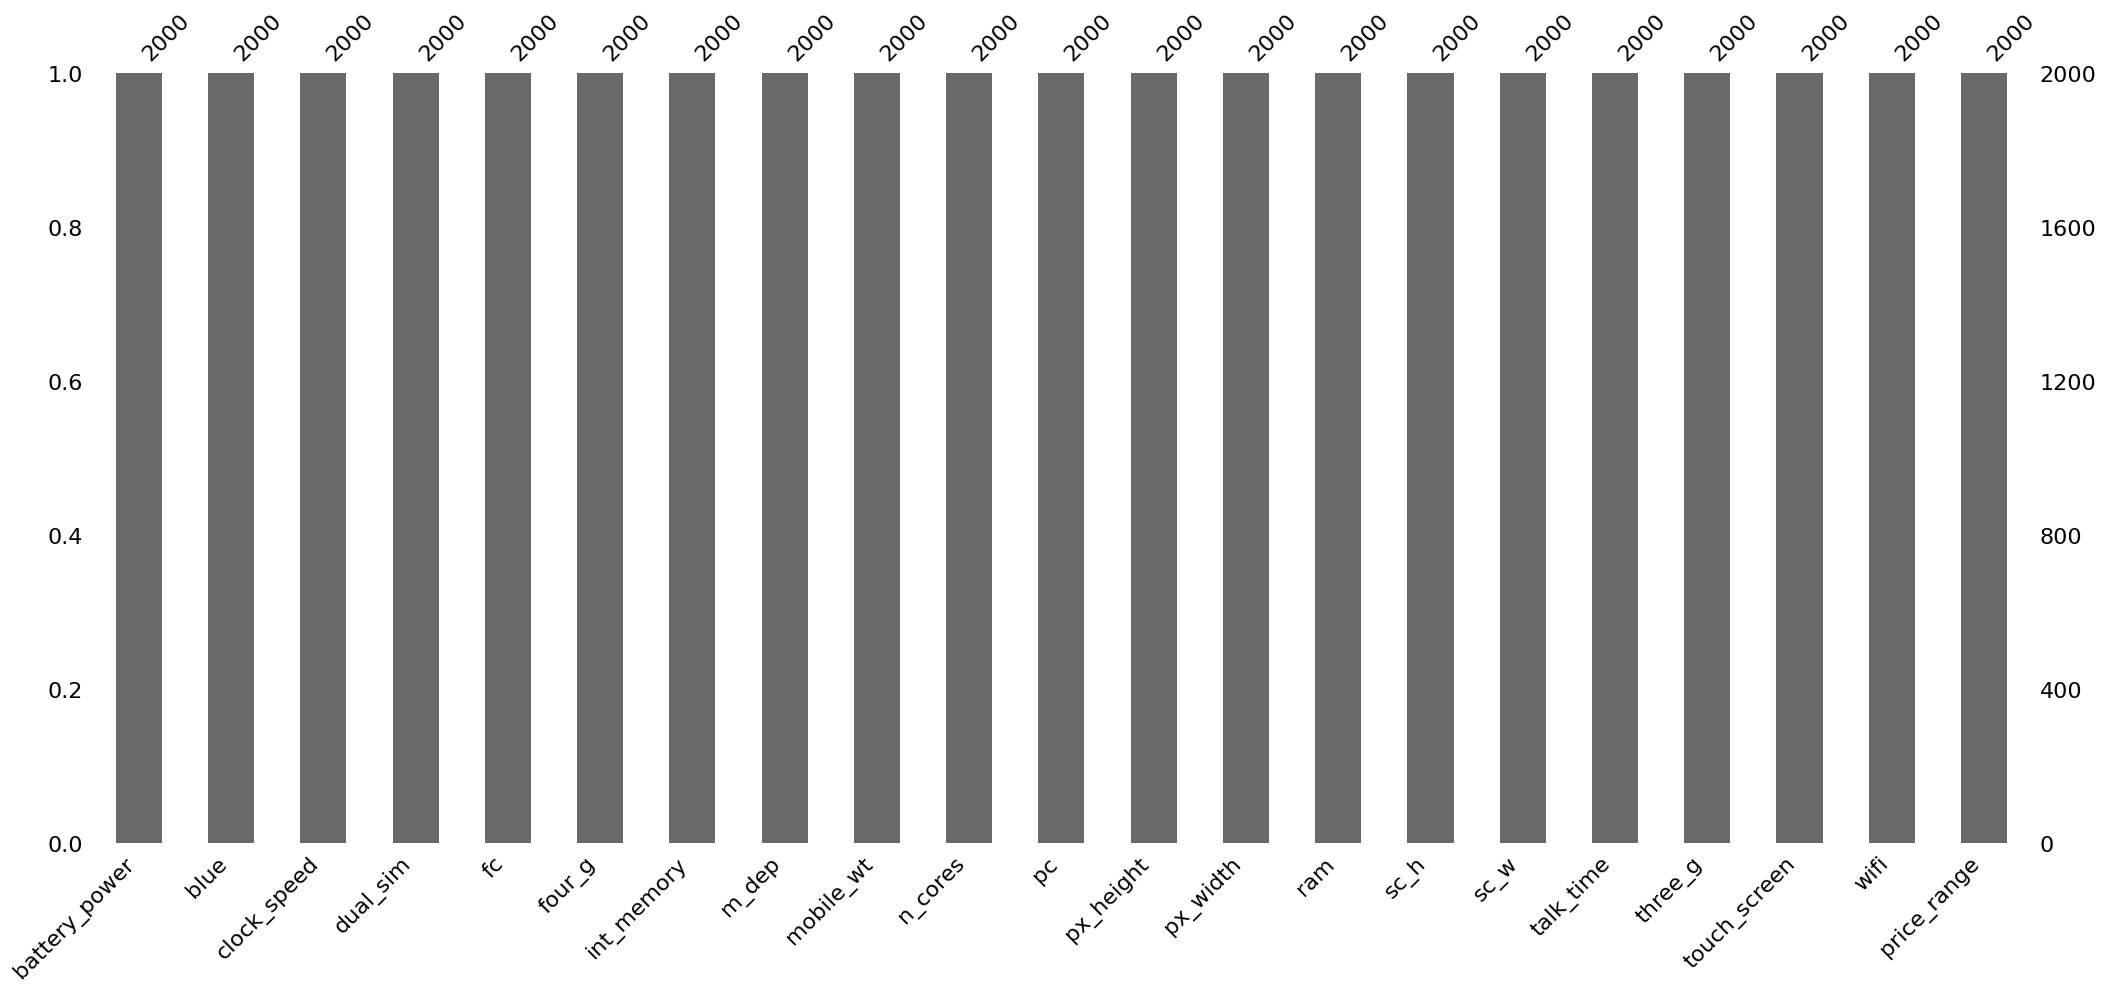

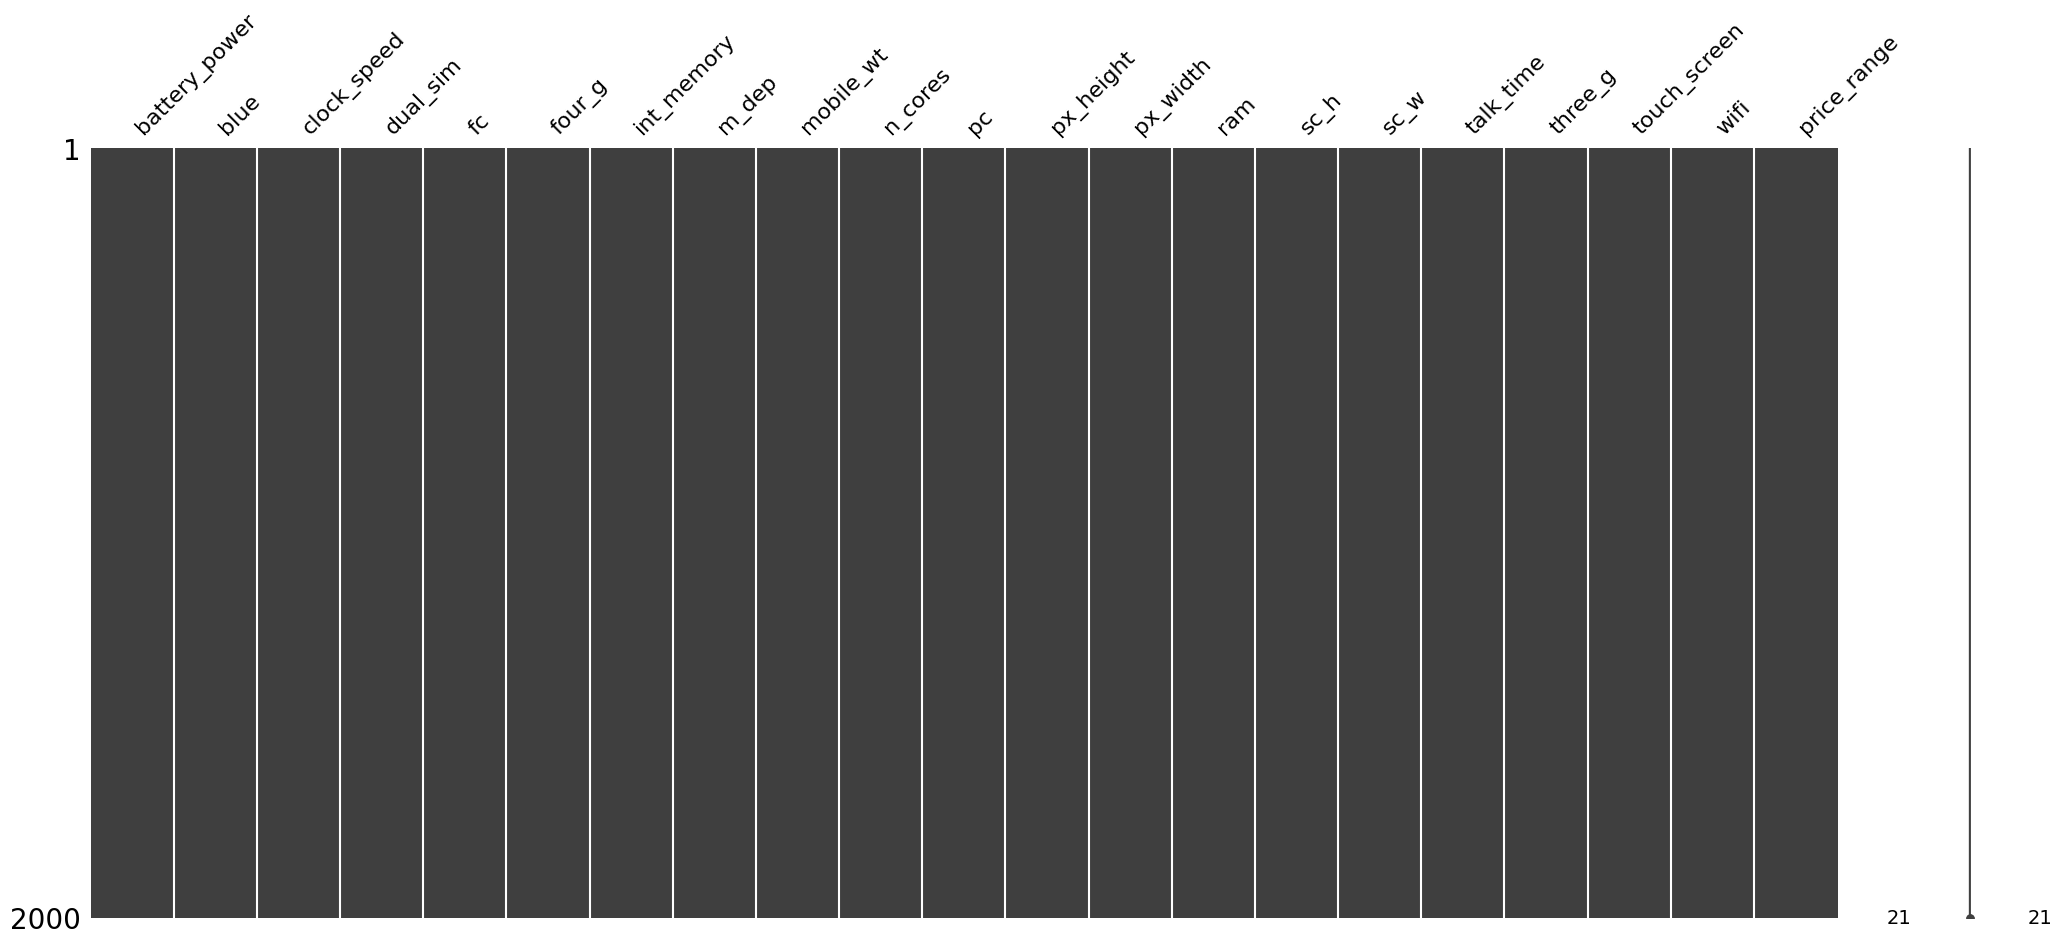

In [ ]:
import pandas as pd
import missingno as msno
import matplotlib.pyplot as plt

df = pd.read_csv('../data/train.csv')

# Tableau : nombre et proportion de valeurs manquantes par colonne
missing = pd.DataFrame({
    'missing_count': df.isnull().sum(),
    'missing_pct': df.isnull().mean() * 100
})
print(missing)

# Visualisation avec missingno
msno.bar(df)      # une barre par colonne, hauteur = valeurs présentes
plt.show()

msno.matrix(df)   # une ligne par observation, blanc = valeur manquante
plt.show()



on remarque ici qu'il ya pas de missong value: si c'eatit le cas je deavis impute avec le median
par exemple 

In [14]:
df.describe(include='all')

,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
count,2000.000000,2000.0000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,...,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,1238.518500,0.4950,1.522250,0.509500,4.309500,0.521500,32.046500,0.501750,140.249000,4.520500,...,645.108000,1251.515500,2124.213000,12.306500,5.767000,11.011000,0.761500,0.503000,0.507000,1.500000
std,439.418206,0.5001,0.816004,0.500035,4.341444,0.499662,18.145715,0.288416,35.399655,2.287837,...,443.780811,432.199447,1084.732044,4.213245,4.356398,5.463955,0.426273,0.500116,0.500076,1.118314
min,501.000000,0.0000,0.500000,0.000000,0.000000,0.000000,2.000000,0.100000,80.000000,1.000000,...,0.000000,500.000000,256.000000,5.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000
25%,851.750000,0.0000,0.700000,0.000000,1.000000,0.000000,16.000000,0.200000,109.000000,3.000000,...,282.750000,874.750000,1207.500000,9.000000,2.000000,6.000000,1.000000,0.000000,0.000000,0.750000
50%,1226.000000,0.0000,1.500000,1.000000,3.000000,1.000000,32.000000,0.500000,141.000000,4.000000,...,564.000000,1247.000000,2146.500000,12.000000,5.000000,11.000000,1.000000,1.000000,1.000000,1.500000
75%,1615.250000,1.0000,2.200000,1.000000,7.000000,1.000000,48.000000,0.800000,170.000000,7.000000,...,947.250000,1633.000000,3064.500000,16.000000,9.000000,16.000000,1.000000,1.000000,1.000000,2.250000
max,1998.000000,1.0000,3.000000,1.000000,19.000000,1.000000,64.000000,1.000000,200.000000,8.000000,...,1960.000000,1998.000000,3998.000000,19.000000,18.000000,20.000000,1.000000,1.000000,1.000000,3.000000


               battery_power      blue  clock_speed  dual_sim        fc  \
battery_power       1.000000  0.011252     0.011482 -0.041847  0.033334   
blue                0.011252  1.000000     0.021419  0.035198  0.003593   
clock_speed         0.011482  0.021419     1.000000 -0.001315 -0.000434   
dual_sim           -0.041847  0.035198    -0.001315  1.000000 -0.029123   
fc                  0.033334  0.003593    -0.000434 -0.029123  1.000000   
four_g              0.015665  0.013443    -0.043073  0.003187 -0.016560   
int_memory         -0.004004  0.041177     0.006545 -0.015679 -0.029133   
m_dep               0.034085  0.004049    -0.014364 -0.022142 -0.001791   
mobile_wt           0.001844 -0.008605     0.012350 -0.008979  0.023618   
n_cores            -0.029727  0.036161    -0.005724 -0.024658 -0.013356   
pc                  0.031441 -0.009952    -0.005245 -0.017143  0.644595   
px_height           0.014901 -0.006872    -0.014523 -0.020875 -0.009990   
px_width           -0.008

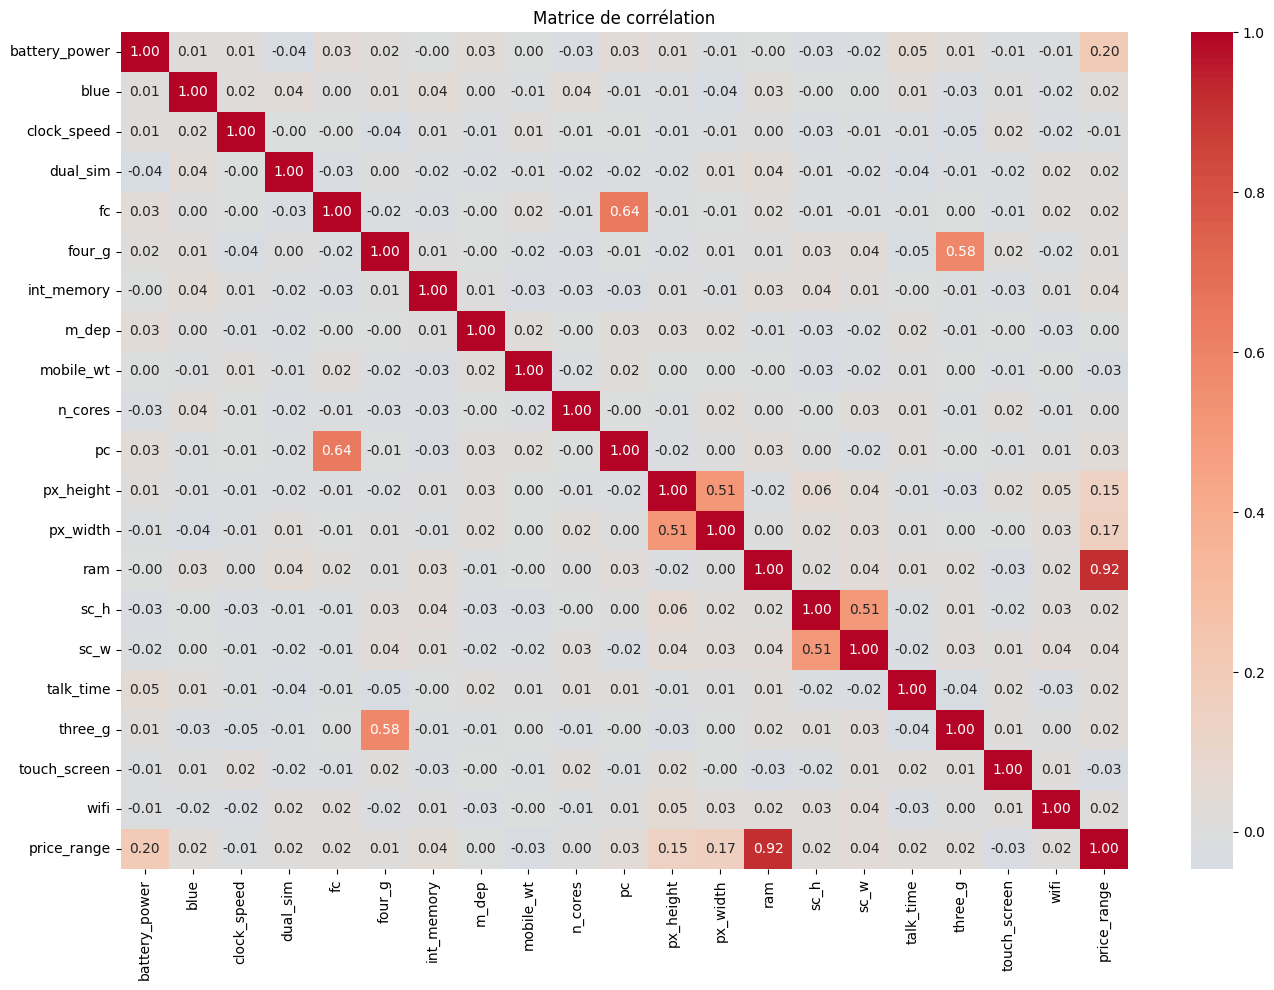

In [16]:
import seaborn as sns
corr = df.corr()
print(corr)

plt.figure(figsize=(14, 10))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Matrice de corrélation')
plt.tight_layout()
plt.show()

les features que l'on notes ici sont: 

les elemnt correles a la target : 

ram , bateries, px_height, px_wight.

les elemtn fortement correles: 

three_g et foru_g, fc et pc, px_heigth et px_width


potenteiielmen faire un features engeneering avec ceci 

ram              0.849622
battery_power    0.030292
px_width         0.029379
px_height        0.027153
int_memory       0.016980
sc_w             0.008335
fc               0.005383
mobile_wt        0.003366
sc_h             0.002110
touch_screen     0.000970
four_g           0.000795
blue             0.000358
three_g          0.000343
dual_sim         0.000322
wifi             0.000214
clock_speed      0.000000
pc               0.000000
n_cores          0.000000
m_dep            0.000000
talk_time        0.000000
dtype: float64


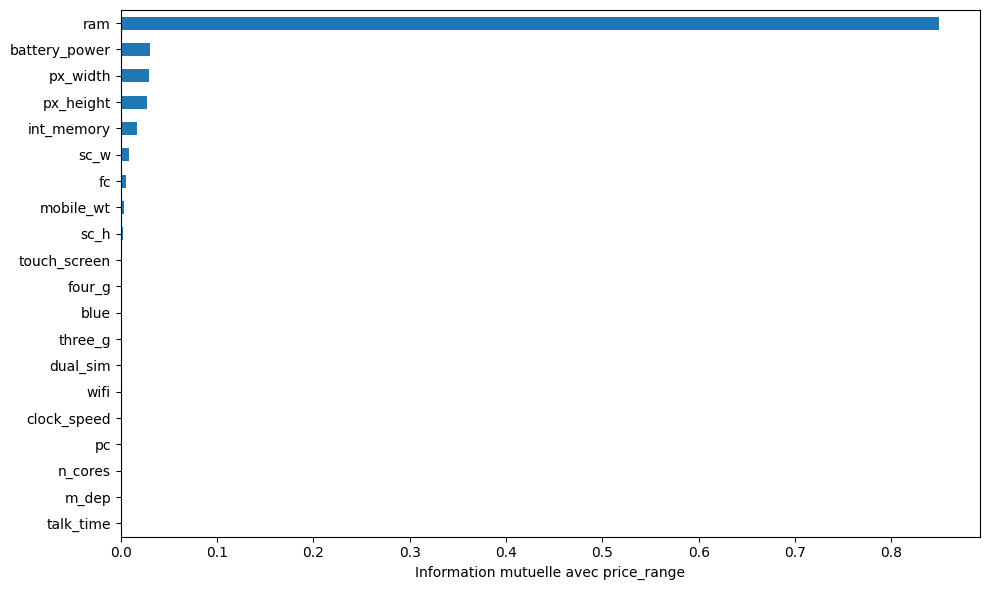

In [18]:
import pandas as pd
from sklearn.feature_selection import mutual_info_classif
X = df.drop(columns='price_range')
y = df['price_range']

# Indiquer les variables discrètes (binaires) pour un calcul correct
discrete = X.columns.isin(['blue', 'dual_sim', 'four_g', 'three_g', 'touch_screen', 'wifi'])

mi = mutual_info_classif(X, y, discrete_features=discrete, random_state=0)
mi = pd.Series(mi, index=X.columns).sort_values(ascending=False)
print(mi)

plt.figure(figsize=(10, 6))
mi.plot(kind='barh')
plt.xlabel('Information mutuelle avec price_range')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

cette etude de la mutal inforamtion confirme que les featuees qui pourrait influence le price range du mobibe 

sont. ram batteries, hegith and wight

explorons comment une varaible px_area  peut exprimer la correlaitin



In [20]:
df['px_area'] = df['px_height'] * df['px_width']
X = df.drop(columns='price_range')
y = df['price_range']

discrete = X.columns.isin(['blue', 'dual_sim', 'four_g', 'three_g', 'touch_screen', 'wifi'])
mi = mutual_info_classif(X, y, discrete_features=discrete, random_state=0)
mi = pd.Series(mi, index=X.columns).sort_values(ascending=False)
print(mi[['ram', 'battery_power', 'px_area', 'px_height', 'px_width']])

ram              0.847588
battery_power    0.033366
px_area          0.018318
px_height        0.027611
px_width         0.030276
dtype: float64


le px_area que je voulais introduire ne fait pas mieux que les precedent donc on va laisser les 4 features de tout a heure

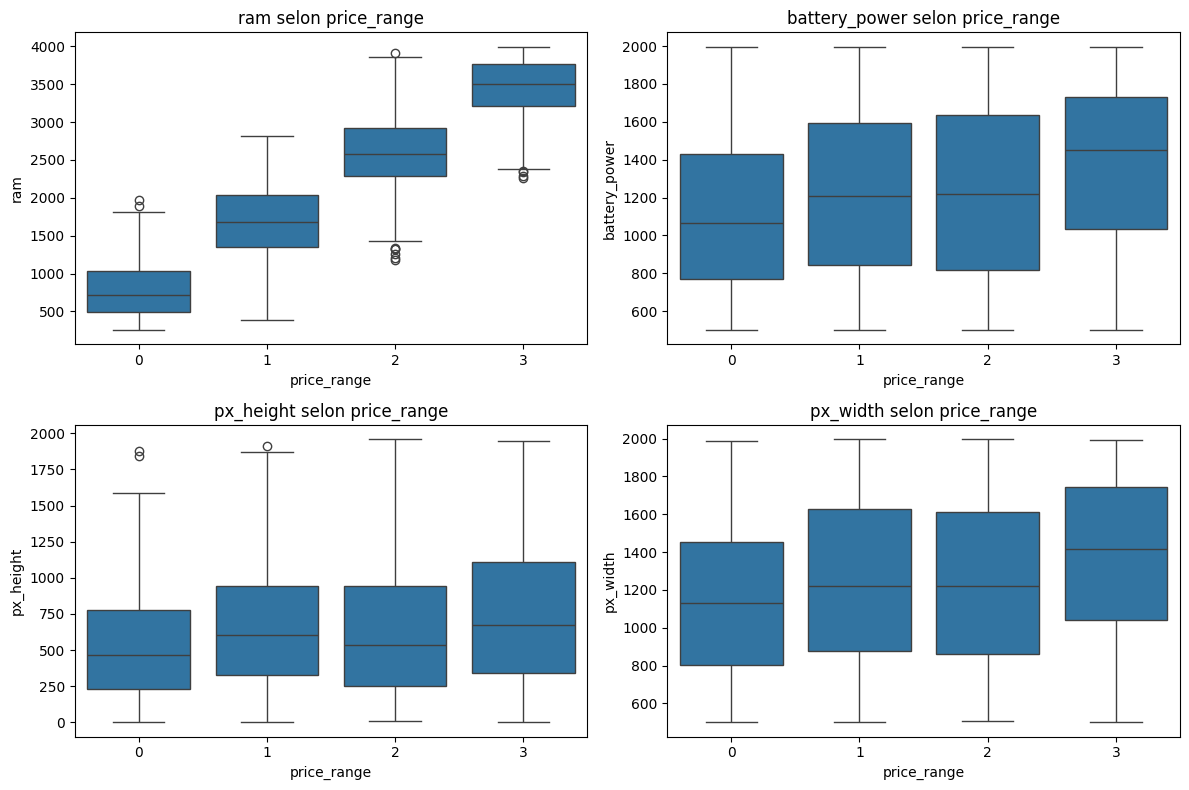

In [26]:

features = ['ram', 'battery_power', 'px_height', 'px_width']

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, col in zip(axes.flatten(), features):
    sns.boxplot(data=df, x='price_range', y=col, ax=ax)
    ax.set_title(f'{col} selon price_range')

plt.tight_layout()
plt.show()

In [ ]:
features = ['ram', 'battery_power', 'px_height', 'px_width']

X = df[features]
y = df['price_range']




,ram,battery_power,px_height,px_width
0,2549,842,20,756
1,2631,1021,905,1988
2,2603,563,1263,1716
3,2769,615,1216,1786
4,1411,1821,1208,1212
...,...,...,...,...
1995,668,794,1222,1890
1996,2032,1965,915,1965
1997,3057,1911,868,1632
1998,869,1512,336,670


ici on prepare les donnes pour l'entrainement

In [32]:
from sklearn.model_selection import train_test_split
xtrain, xtest, ytrain, ytest = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
xtrain_scaled = scaler.fit_transform(xtrain)
xtest_scaled = scaler.transform(xtest)


In [34]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

model = LogisticRegression(random_state=42, max_iter=1000)
model.fit(xtrain_scaled, ytrain)

# AUC multiclasse : one-vs-rest, moyenne sur les 4 classes
auc_scores = cross_val_score(model, xtrain_scaled, ytrain, cv=5, scoring='roc_auc_ovr')
print(f"AUC Scores: {auc_scores}")
print(f"Mean AUC Score: {auc_scores.mean():.4f}")
print(f"Standard Deviation: {auc_scores.std():.4f}")

AUC Scores: [0.99798177 0.99714844 0.99751302 0.99802083 0.99834635]
Mean AUC Score: 0.9978
Standard Deviation: 0.0004


l'accuracy est top sur le trraining voyons voir sur le test

In [35]:
ypred = model.predict(xtest_scaled)
auc_score = cross_val_score(model, xtest_scaled, ytest, cv=5, scoring='roc_auc_ovr')
print(f"Test AUC Scores: {auc_score}")
print(f"Mean Test AUC Score: {auc_score.mean():.4f}")
print(f"Standard Deviation of Test AUC Scores: {auc_score.std():.4f}")

Test AUC Scores: [0.99875    0.99541667 0.99583333 0.99416667 0.990625  ]
Mean Test AUC Score: 0.9950
Standard Deviation of Test AUC Scores: 0.0026


wow top comme prediction 



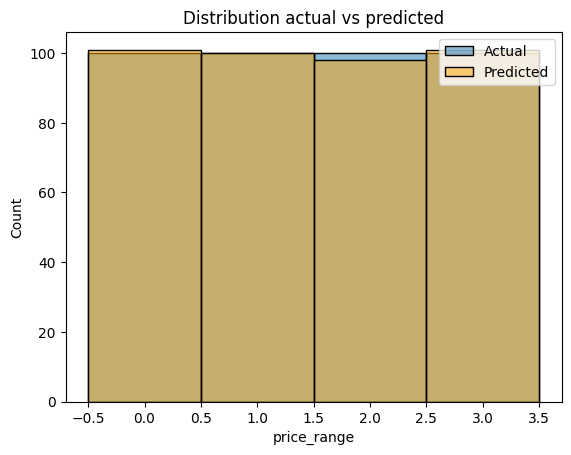

In [37]:
import seaborn as sns

sns.histplot(ytest, bins=4, discrete=True, alpha=0.5, label='Actual')
sns.histplot(ypred, bins=4, discrete=True, alpha=0.5, label='Predicted', color='orange')
plt.legend()
plt.title("Distribution actual vs predicted")
plt.show()